# 10-6. 구간 그림 (원 스케일 / GARCH / 자체 구간)

GARCH 원 스케일 자체 구간(`점예측 ± z x σ_h`)을 예측 시점(origin) 5개에서 그린다. origin은 임의로 골랐다(평온한 시기, 급등 전후 포함).
- 남색: 훈련 마지막 16분기, 진한 선: 점예측, 부채꼴: 90·80·60·40% 구간
- 빨강: 이후 실제값 (90% 구간 안 = 동그라미, 밖 = X)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)

d = pd.read_pickle("../cache/cache_96_garch_orig_df.pkl")
s = d[d["방식"] == "자체"].set_index(["origin", "h"])
ORIGINS = [35, 42, 47, 51, 56]
for o in ORIGINS:
    print(f"origin {o}: 훈련 ~{quarters[o - 1]}, 예측 {quarters[o]} ~ {quarters[o + 3]}")

origin 35: 훈련 ~2019Q3, 예측 2019Q4 ~ 2020Q3
origin 42: 훈련 ~2021Q2, 예측 2021Q3 ~ 2022Q2
origin 47: 훈련 ~2022Q3, 예측 2022Q4 ~ 2023Q3
origin 51: 훈련 ~2023Q3, 예측 2023Q4 ~ 2024Q3
origin 56: 훈련 ~2024Q4, 예측 2025Q1 ~ 2025Q4


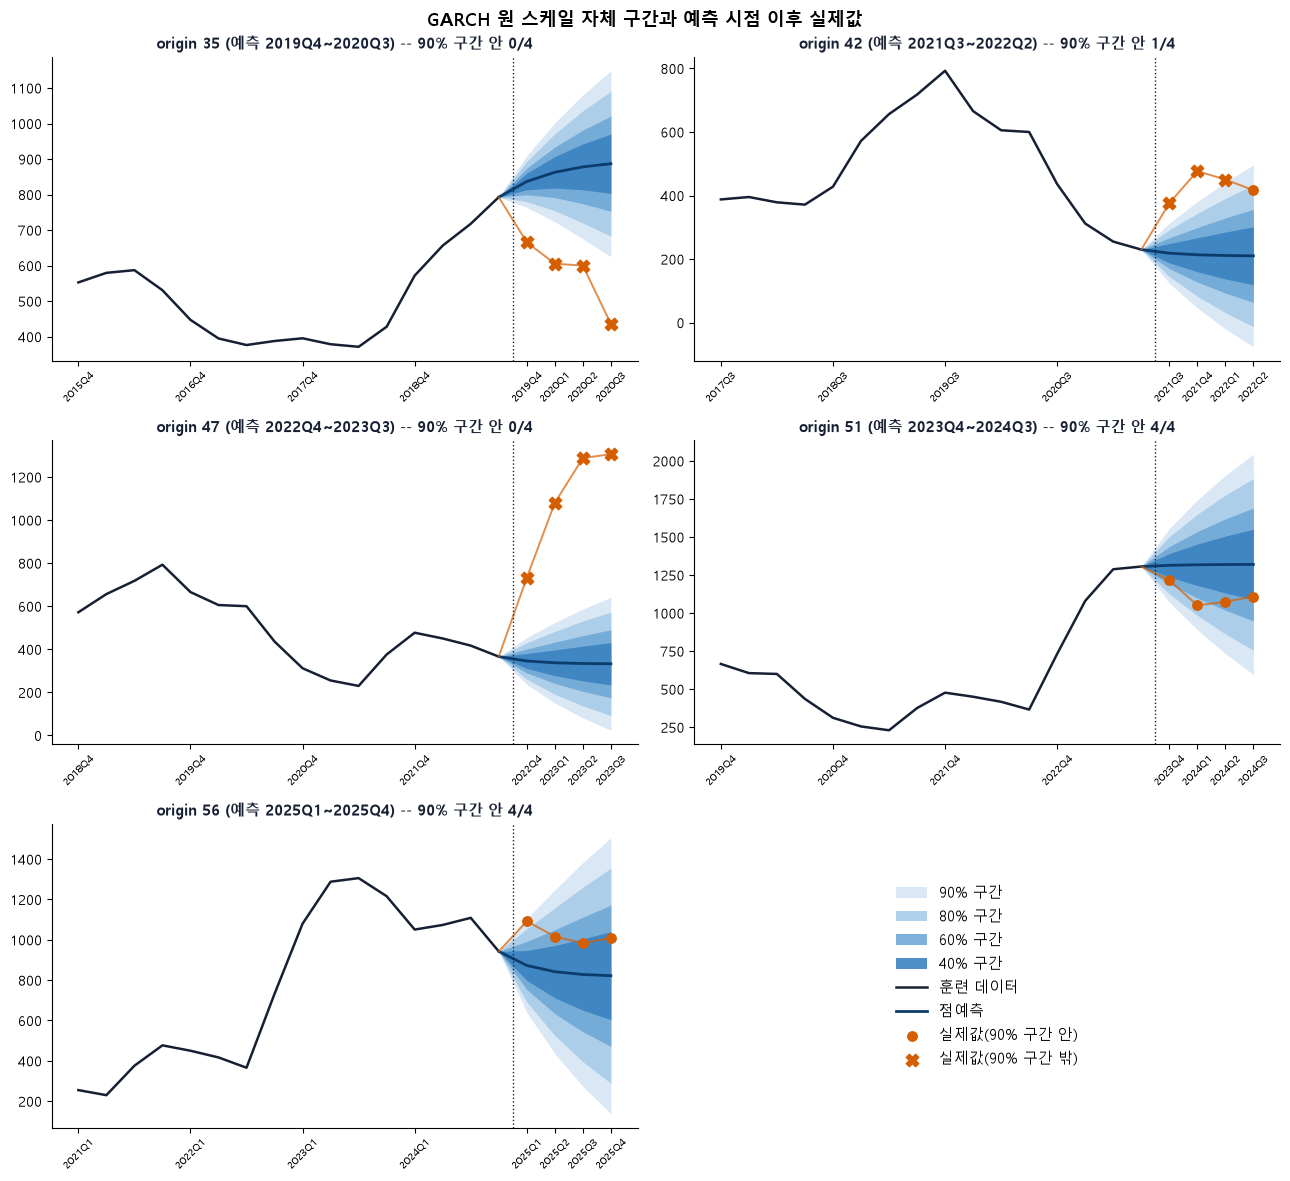

In [2]:
HIST = 16
BANDS = [(0.90, "#D6E6F4"), (0.80, "#A9CCE8"), (0.60, "#6FA8D6"), (0.40, "#3B82C0")]   # 90, 80, 60, 40% 구간


def draw(ax, o):
    rows = s.loc[o]                               # h=1..4
    fc, sig, act = rows["fc"].values, rows["sigma_model"].values, rows["actual"].values
    x_hist = np.arange(o - HIST, o)
    x_fc = np.arange(o, o + 4)
    for conf, col in BANDS:
        z = stats.norm.ppf(0.5 + conf / 2)
        # 마지막 훈련값에서 시작해 부채꼴로 이어 그린다
        xs = np.r_[o - 1, x_fc]
        lo = np.r_[vals[o - 1], fc - z * sig]
        hi = np.r_[vals[o - 1], fc + z * sig]
        ax.fill_between(xs, lo, hi, color=col, alpha=0.9, linewidth=0, label=f"{int(conf * 100)}% 구간")
    ax.plot(x_hist, vals[o - HIST:o], color="#172033", linewidth=1.8, label="훈련 데이터")
    ax.plot(np.r_[o - 1, x_fc], np.r_[vals[o - 1], fc], color="#0B3C6B", linewidth=2, label="점예측")
    lo90, hi90 = rows["lo"].values, rows["hi"].values
    inside = (act >= lo90) & (act <= hi90)
    ax.plot(np.r_[o - 1, x_fc], np.r_[vals[o - 1], act], color="#D55E00", linewidth=1.4, alpha=0.7)
    ax.scatter(x_fc[inside], act[inside], color="#D55E00", s=46, zorder=5, label="실제값(90% 구간 안)")
    ax.scatter(x_fc[~inside], act[~inside], color="#D55E00", marker="X", s=80, zorder=5, label="실제값(90% 구간 밖)")
    ax.axvline(o - 0.5, color="#172033", linestyle=":", linewidth=1)
    ax.set_xticks(np.r_[x_hist[::4], x_fc])
    ax.set_xticklabels([quarters[i] for i in np.r_[x_hist[::4], x_fc]], fontsize=7, rotation=45)
    ax.set_title(f"origin {o} (예측 {quarters[o]}~{quarters[o + 3]}) -- 90% 구간 안 {int(inside.sum())}/4", fontsize=10.5, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, o in zip(axes.ravel(), ORIGINS):
    draw(ax, o)
h_, l_ = axes[0, 0].get_legend_handles_labels()
axes[2, 1].axis("off")
axes[2, 1].legend(h_, l_, loc="center", frameon=False, fontsize=11)
fig.suptitle("GARCH 원 스케일 자체 구간과 예측 시점 이후 실제값", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## 5개 origin 요약

In [3]:
rows = []
for o in ORIGINS:
    r = s.loc[o]
    for h in range(1, 5):
        x = r.loc[h]
        rows.append({"origin": o, "예측 분기": quarters[o + h - 1], "h": h, "점예측": x["fc"], "실제값": x["actual"], "오차": x["actual"] - x["fc"],
                     "90% 하한": x["lo"], "90% 상한": x["hi"], "구간 안": "O" if x["lo"] <= x["actual"] <= x["hi"] else "X",
                     "오차÷σ": (x["actual"] - x["fc"]) / x["sigma_model"]})
tab = pd.DataFrame(rows)
display(tab.round(1).set_index(["origin", "예측 분기", "h"]))
print("5개 origin x 4 = 20개 중 90% 구간 안:", int((tab["구간 안"] == "O").sum()), "개")

점예측     실제값     오차  90% 하한  90% 상한 구간 안  오차÷σ
origin 예측 분기  h                                                  
35     2019Q4 1   836.8   665.6 -171.2   763.8   909.8    X  -3.9
       2020Q1 2   862.7   605.4 -257.3   723.6  1001.8    X  -3.0
       2020Q2 3   877.9   599.9 -278.0   675.3  1080.6    X  -2.3
       2020Q3 4   886.9   435.9 -451.0   625.2  1148.5    X  -2.8
42     2021Q3 1   218.5   375.7  157.2   124.0   312.9    X   2.7
       2021Q4 2   213.4   476.9  263.4    46.1   380.7    X   2.6
       2022Q1 3   211.1   450.1  239.0   -19.7   442.0    X   1.7
       2022Q2 4   210.1   416.9  206.8   -76.2   496.4    O   1.2
47     2022Q4 1   345.4   732.2  386.8   236.7   454.1    X   5.9
       2023Q1 2   337.2  1080.0  742.8   150.0   524.3    X   6.5
       2023Q2 3   333.9  1288.0  954.1    81.0   586.7    X   6.2
       2023Q3 4   332.6  1305.8  973.2    23.8   641.3    X   5.2
51     2023Q4 1  1313.7  1216.1  -97.6  1072.1  1555.4    O  -0.7
       2024Q1 2  1317.3  1050.8 -266.5   891.1  1743.5    O  -1.0
       2024Q2 3  1318.9  1073.7 -245.2   733.2  1904.6    O  -0.7
       2024Q3 4  1319.6  1108.8 -210.8   595.3  2043.9    O  -0.5
56     2025Q1 1   872.8  1092.4  219.6   639.8  1105.8    O   1.6
       2025Q2 2   841.8  1016.1  174.3   435.8  1247.8    O   0.7
       2025Q3 3   828.1   983.8  155.7   273.2  1383.1    O   0.5
       2025Q4 4   822.0  1009.1  187.0   137.8  1506.3    O   0.4

5개 origin x 4 = 20개 중 90% 구간 안: 9 개


## 결론

**5개 origin 20개 예측 중 90% 구간 안은 9개이고, 시기에 따라 갈린다.**

| origin | 예측 구간 | 90% 구간 안 | 특징 |
|---|---|---|---|
| 35 | 2019Q4~2020Q3 | 0/4 | 점예측은 소폭 상승, 실제값은 하락 |
| 42 | 2021Q3~2022Q2 | 1/4 | 낮은 수준에서 반등 |
| 47 | 2022Q4~2023Q3 | 0/4 | 급등(약 730 -> 1,306), +5~6σ |
| 51 | 2023Q4~2024Q3 | 4/4 | 고점 이후 하락했으나 구간 안 |
| 56 | 2025Q1~2025Q4 | 4/4 | 구간 안 |

- 점예측은 거의 평평하고, 구간은 h가 커질수록 부채꼴로 넓어진다.
- 한 방향으로 크게 움직인 origin 35, 47은 모두 구간 밖이고, 조용한 51, 56은 모두 구간 안이다.
- 한계: 그림용 사례라 대표성이 없다. 전체 22개 origin의 90% 커버리지는 75.0%다.